# Практичне заняття № 6 — Метод k-середніх та ієрархічна кластеризація

**Завдання.** Виконати реалізацію алгоритмів k-середніх та ієрархічної
кластеризації на одному з датасетів
[Kaggle: security](https://www.kaggle.com/datasets?search=security).
Дослідити залежність точності методу від параметрів даних.

**Датасет: UGRansome** — той самий, що в практичних заняттях № 2, № 3 і № 5.
Тут це особливо цінно: ми **знаємо** справжні мітки (`S`/`A`/`SS`) і знаємо, що
методи з учителем досягають на них 99 %. Тож можна поставити питання, на яке
зазвичай відповісти неможливо: **чи знаходить кластеризація саме ту структуру,
яку шукає класифікація?**

## Принципова відмінність від попередніх робіт

Це перша задача **навчання без учителя**. Мітки не використовуються для
побудови моделі — лише для перевірки постфактум. Через це змінюється саме поняття
«точності»:

- **Внутрішні метрики** (інерція, силует) оцінюють якість кластерів самих по
  собі: наскільки вони щільні й відокремлені. Міток не потребують.
- **Зовнішні метрики** (ARI, NMI) порівнюють знайдені кластери з відомими
  класами. Потребують міток, тому в реальній задачі кластеризації недоступні.

ARI (Adjusted Rand Index) дорівнює 0 для випадкового розбиття і 1 для повного
збігу.

In [1]:
# --- Підготовка даних -------------------------------------------------------
# Ноутбук має запускатися і локально, і в Colab. Якщо потрібного файлу немає,
# він завантажується з Kaggle. Форму таблиці перевіряємо одразу: Kaggle може
# оновити версію набору, і краще впасти тут, ніж мовчки отримати інші числа,
# ніж у звіті.
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path


def _in_colab():
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        # find_spec імпортує батьківський пакет; без нього — це не Colab
        return False


IN_COLAB = _in_colab()
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)

# (локальна назва, slug на Kaggle, файл у наборі, колонок, рядків, кодування)
DATASETS = [
    ('ugransome.csv', 'nkongolo/ugransome-dataset',
     'final(2).csv', 14, 149043, 'utf-8')
]


def _ensure_packages():
    """У Colab більшість пакетів уже є; доставляємо лише те, чого бракує."""
    missing = [p for p in ("pandas", "sklearn", "matplotlib", "seaborn", "kagglehub")
               if importlib.util.find_spec(p) is None]
    if missing:
        names = {"sklearn": "scikit-learn"}
        pkgs = [names.get(m, m) for m in missing]
        print("встановлюю:", ", ".join(pkgs))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


def _check(path, ncols, nrows, encoding):
    # Перевіряємо і колонки, і рядки: нова версія набору може зберегти структуру,
    # але змінити обсяг — і числа у звіті тихо перестануть збігатися.
    import pandas as pd
    got = pd.read_csv(path, encoding=encoding).shape
    if got != (nrows, ncols):
        raise ValueError(f"{path.name}: очікували {nrows}×{ncols}, отримали {got[0]}×{got[1]}")


def _ensure(local, slug, member, ncols, nrows, encoding):
    dst = DATA / local
    if dst.exists():
        _check(dst, ncols, nrows, encoding)
        print(f"на місці: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    if importlib.util.find_spec("kagglehub"):
        import kagglehub
        print(f"завантажую {slug} …")
        root = Path(kagglehub.dataset_download(slug))
        src = next(iter(root.rglob(member)), None)
        if src is None:   # назву файлу в наборі могли змінити — беремо найбільший CSV
            src = max(root.rglob("*.csv"), key=lambda f: f.stat().st_size)
        shutil.copy(src, dst)
        _check(dst, ncols, nrows, encoding)
        print(f"готово: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    raise FileNotFoundError(
        f"{dst} не знайдено. Візьміть набір за адресою "
        f"https://www.kaggle.com/datasets/{slug} і покладіть файл у {DATA}/ "
        f"під назвою {local}."
    )


if IN_COLAB:
    _ensure_packages()
for _args in DATASETS:
    _ensure(*_args)

на місці: data/ugransome.csv (10.0 МБ)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from pathlib import Path

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, homogeneity_score, completeness_score,
                             confusion_matrix)
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

RANDOM_STATE = 42
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
np.random.seed(RANDOM_STATE)

N_MAIN = 20000    # для k-середніх
N_HIER = 5000     # ієрархічна кластеризація має складність O(n²) за пам'яттю

## 1. Дані та підготовка

In [3]:
df = pd.read_csv("data/ugransome.csv")
y_true_all = df["Prediction"].copy()
X_all = df.drop(columns=["Prediction"]).copy()
for col in X_all.select_dtypes(include=["object", "string"]).columns:
    X_all[col] = X_all[col].astype("category").cat.codes

X, _, y_true, _ = train_test_split(X_all, y_true_all, train_size=N_MAIN,
                                   random_state=RANDOM_STATE, stratify=y_true_all)
X = X.reset_index(drop=True); y_true = y_true.reset_index(drop=True)

# Кластеризація спирається на відстані, тож масштабування обов'язкове.
# У практичному занятті № 5 показано, що для kNN воно могло шкодити, бо
# найширша ознака USD була й найінформативнішою. Тут учителя немає, і
# «випадково правильне» зважування покладатися ні на що не дозволяє.
scaler = StandardScaler()
Z = scaler.fit_transform(X)

print(f"Розмір: {X.shape[0]} × {X.shape[1]}")
print(f"Справжні класи: {dict(y_true.value_counts())}")

Розмір: 20000 × 13
Справжні класи: {'S': np.int64(8908), 'A': np.int64(5711), 'SS': np.int64(5381)}


## 2. Метод k-середніх: вибір кількості кластерів

Алгоритм мінімізує **інерцію** — суму квадратів відстаней від точок до центрів
своїх кластерів. Інерція монотонно спадає зі зростанням $k$, тому сама по собі
оптимального $k$ не вказує; шукають «лікоть» — точку, після якої спад
уповільнюється.

**Силует** оцінює, наскільки точка ближча до свого кластера, ніж до сусіднього.
Змінюється від −1 до 1; значення близько 0 означають, що кластери перекриваються.

In [4]:
k_range = range(2, 13)
km_rows = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(Z)
    km_rows.append({
        "k": k,
        "Інерція": km.inertia_,
        "Силует": silhouette_score(Z, km.labels_, sample_size=5000, random_state=RANDOM_STATE),
        "ARI": adjusted_rand_score(y_true, km.labels_),
        "NMI": normalized_mutual_info_score(y_true, km.labels_),
        "Однорідність": homogeneity_score(y_true, km.labels_),
        "Повнота": completeness_score(y_true, km.labels_),
    })

km_df = pd.DataFrame(km_rows)
km_df.to_csv("data/kmeans-k-sweep.csv", index=False)
best_sil = int(km_df.loc[km_df["Силует"].idxmax(), "k"])
best_ari = int(km_df.loc[km_df["ARI"].idxmax(), "k"])
print(f"Найкращий силует (внутрішня метрика): k = {best_sil} ({km_df['Силует'].max():.4f})")
print(f"Найкращий ARI    (зовнішня метрика): k = {best_ari} ({km_df['ARI'].max():.4f})")
km_df.round(4)

Найкращий силует (внутрішня метрика): k = 10 (0.1746)
Найкращий ARI    (зовнішня метрика): k = 4 (0.2480)


,k,Інерція,Силует,ARI,NMI,Однорідність,Повнота
0,2,232613.8243,0.1337,0.0867,0.1531,0.1200,0.2112
1,3,215581.1236,0.1054,0.2010,0.2159,0.2176,0.2141
2,4,198235.0646,0.1167,0.2480,0.2614,0.2926,0.2361
3,5,181427.0282,0.1359,0.1803,0.2281,0.2692,0.1979
4,6,170043.0348,0.1496,0.1246,0.1768,0.2282,0.1443
5,7,155371.4113,0.1583,0.1227,0.1767,0.2298,0.1435
6,8,147457.3213,0.1732,0.1043,0.1842,0.2498,0.1459
7,9,140008.7206,0.1714,0.1170,0.2136,0.3071,0.1638
8,10,133994.9804,0.1746,0.1216,0.2231,0.3345,0.1674
9,11,129855.5149,0.1724,0.1191,0.2128,0.3330,0.1564


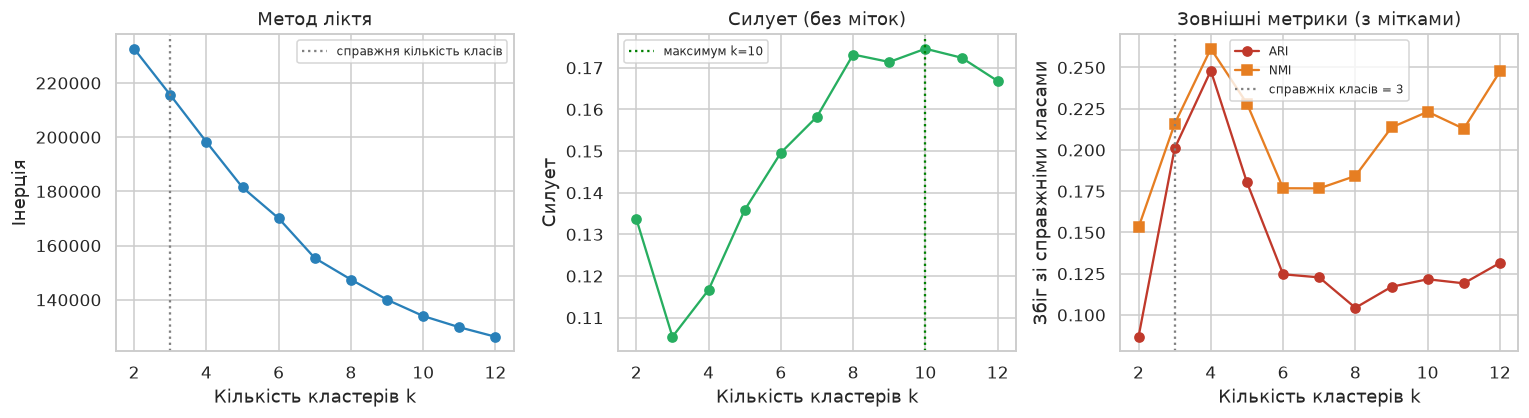

In [5]:
# --- Рисунок 1: вибір k ---
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

axes[0].plot(km_df["k"], km_df["Інерція"], "o-", color="#2980b9")
axes[0].axvline(3, color="gray", linestyle=":", label="справжня кількість класів")
axes[0].set_xlabel("Кількість кластерів k"); axes[0].set_ylabel("Інерція")
axes[0].set_title("Метод ліктя"); axes[0].legend(fontsize=8)

axes[1].plot(km_df["k"], km_df["Силует"], "o-", color="#27ae60")
axes[1].axvline(best_sil, color="green", linestyle=":", label=f"максимум k={best_sil}")
axes[1].set_xlabel("Кількість кластерів k"); axes[1].set_ylabel("Силует")
axes[1].set_title("Силует (без міток)"); axes[1].legend(fontsize=8)

axes[2].plot(km_df["k"], km_df["ARI"], "o-", color="#c0392b", label="ARI")
axes[2].plot(km_df["k"], km_df["NMI"], "s-", color="#e67e22", label="NMI")
axes[2].axvline(3, color="gray", linestyle=":", label="справжніх класів = 3")
axes[2].set_xlabel("Кількість кластерів k"); axes[2].set_ylabel("Збіг зі справжніми класами")
axes[2].set_title("Зовнішні метрики (з мітками)"); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(ASSETS / "01-choosing-k.png", bbox_inches="tight")
plt.show()

### Внутрішні та зовнішні метрики не узгоджуються

Це головне спостереження роботи. Силует радить одну кількість кластерів, ARI —
іншу, а справжніх класів три. У реальній задачі доступний **лише силует**, тож
керуючись ним, ми обрали б кількість кластерів, яка гірше відповідає дійсній
структурі даних.

## 3. Наскільки кластери відповідають класам

In [6]:
km3 = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(Z)
ct = pd.crosstab(y_true, km3.labels_, rownames=["Справжній клас"], colnames=["Кластер"])
print("Таблиця відповідності (k = 3):")
print(ct.to_string())
print()
print(f"ARI = {adjusted_rand_score(y_true, km3.labels_):.4f}")
print(f"NMI = {normalized_mutual_info_score(y_true, km3.labels_):.4f}")
print(f"Однорідність = {homogeneity_score(y_true, km3.labels_):.4f}  "
      f"(наскільки кластер складається з одного класу)")
print(f"Повнота      = {completeness_score(y_true, km3.labels_):.4f}  "
      f"(наскільки клас зібраний в один кластер)")
print()
print("Для порівняння: методи з учителем на цих самих даних дають ~0.99 точності.")

Таблиця відповідності (k = 3):
Кластер            0     1     2
Справжній клас                  
A                433  1945  3333
S               4714  3535   659
SS               328  1306  3747

ARI = 0.2010
NMI = 0.2159
Однорідність = 0.2176  (наскільки кластер складається з одного класу)
Повнота      = 0.2141  (наскільки клас зібраний в один кластер)

Для порівняння: методи з учителем на цих самих даних дають ~0.99 точності.


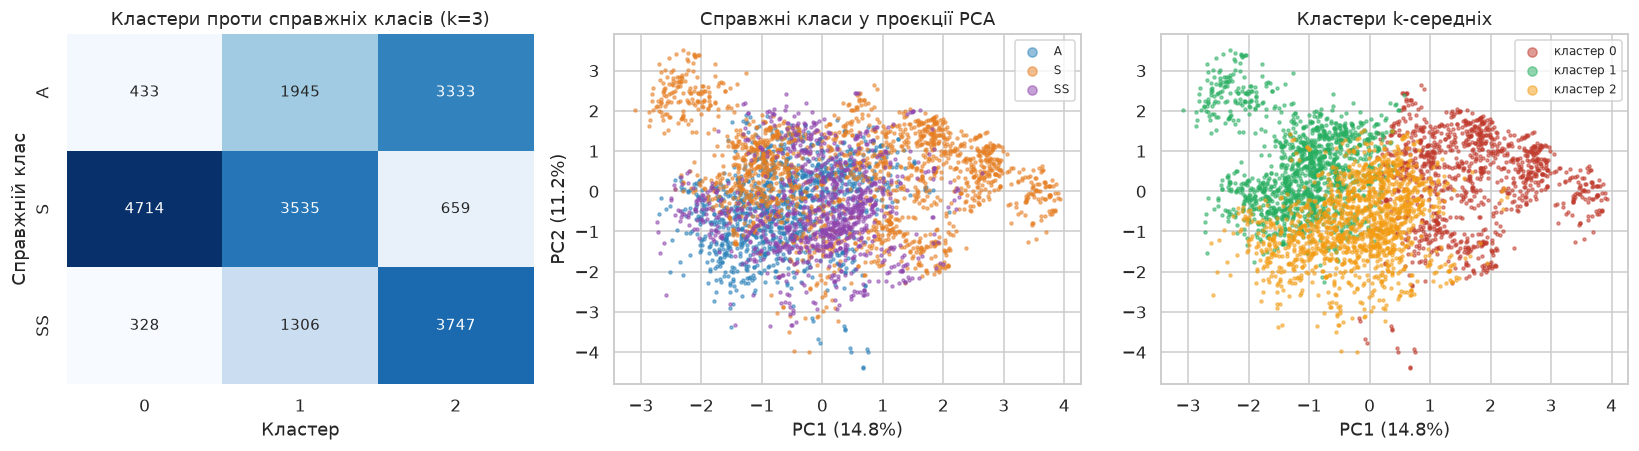

Двома компонентами PCA пояснено лише 26.0% дисперсії


In [7]:
# --- Рисунок 2: таблиця відповідності та проєкція PCA ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Кластери проти справжніх класів (k=3)")

pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Z)
sub = np.random.RandomState(RANDOM_STATE).choice(len(P), 4000, replace=False)

for lab, col in zip(sorted(y_true.unique()), ["#2980b9", "#e67e22", "#8e44ad"]):
    m = (y_true.iloc[sub] == lab).values
    axes[1].scatter(P[sub][m, 0], P[sub][m, 1], s=4, alpha=0.5, label=lab, color=col)
axes[1].set_title("Справжні класи у проєкції PCA"); axes[1].legend(fontsize=8, markerscale=3)
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")

for cl, col in zip(range(3), ["#c0392b", "#27ae60", "#f39c12"]):
    m = (km3.labels_[sub] == cl)
    axes[2].scatter(P[sub][m, 0], P[sub][m, 1], s=4, alpha=0.5, label=f"кластер {cl}", color=col)
axes[2].set_title("Кластери k-середніх"); axes[2].legend(fontsize=8, markerscale=3)
axes[2].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")

plt.tight_layout()
plt.savefig(ASSETS / "02-clusters-vs-classes.png", bbox_inches="tight")
plt.show()
print(f"Двома компонентами PCA пояснено лише {pca.explained_variance_ratio_.sum():.1%} дисперсії")

## 4. Ієрархічна кластеризація

Агломеративний підхід: кожна точка спочатку є окремим кластером, далі найближчі
пари послідовно об'єднуються, доки не залишиться один кластер. Результат —
дерево (дендрограма), яке можна «зрізати» на будь-якій висоті.

**Спосіб зв'язування (linkage)** визначає, як вимірюється відстань між кластерами:

- `ward` — мінімізує приріст внутрішньокластерної дисперсії;
- `complete` — відстань між найдальшими точками кластерів;
- `average` — середня відстань між усіма парами;
- `single` — відстань між найближчими точками; схильний до «ланцюгового ефекту».

Складність за пам'яттю — $O(n^2)$, тому працюємо на підвибірці 5 000 записів.

In [8]:
idx = np.random.RandomState(RANDOM_STATE).choice(len(Z), N_HIER, replace=False)
Zh, yh = Z[idx], y_true.iloc[idx].reset_index(drop=True)

link_rows = []
for method in ["ward", "complete", "average", "single"]:
    t0 = time.time()
    model = AgglomerativeClustering(n_clusters=3, linkage=method).fit(Zh)
    elapsed = time.time() - t0
    sizes = np.bincount(model.labels_)
    link_rows.append({
        "Зв'язування": method,
        "ARI": adjusted_rand_score(yh, model.labels_),
        "NMI": normalized_mutual_info_score(yh, model.labels_),
        "Силует": silhouette_score(Zh, model.labels_),
        "Найбільший кластер": sizes.max() / len(yh),
        "Час, с": elapsed,
    })

link_df = pd.DataFrame(link_rows).set_index("Зв'язування")
link_df.to_csv("data/linkage.csv")
link_df.round(4)

,ARI,NMI,Силует,Найбільший кластер,"Час, с"
Зв'язування,,,,,
ward,0.1270,0.1864,0.1363,0.5752,0.8356
complete,0.0018,0.0106,0.3998,0.9952,0.7968
average,0.0018,0.0106,0.4803,0.9952,0.8284
single,0.0005,0.0023,0.3444,0.9986,0.2390


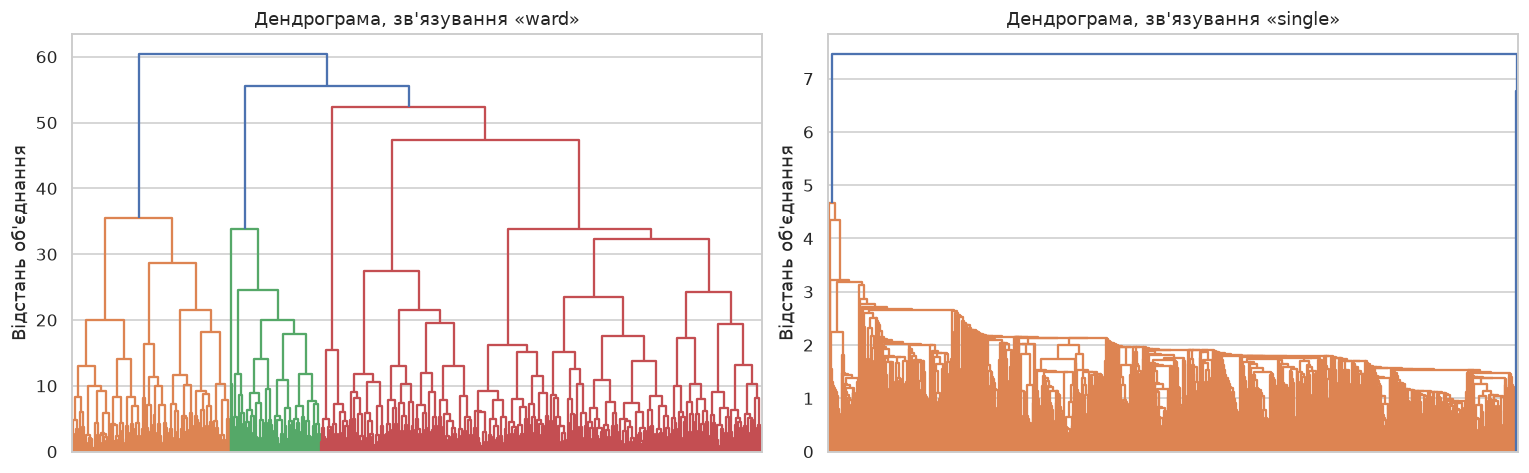

In [9]:
# --- Рисунок 3: дендрограма ---
idx_d = np.random.RandomState(RANDOM_STATE).choice(len(Zh), 1500, replace=False)
Zd = Zh[idx_d]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, method in zip(axes, ["ward", "single"]):
    L = linkage(Zd, method=method)
    dendrogram(L, ax=ax, no_labels=True, color_threshold=L[-2, 2])
    ax.set_title(f"Дендрограма, зв'язування «{method}»")
    ax.set_ylabel("Відстань об'єднання")
plt.tight_layout()
plt.savefig(ASSETS / "03-dendrogram.png", bbox_inches="tight")
plt.show()

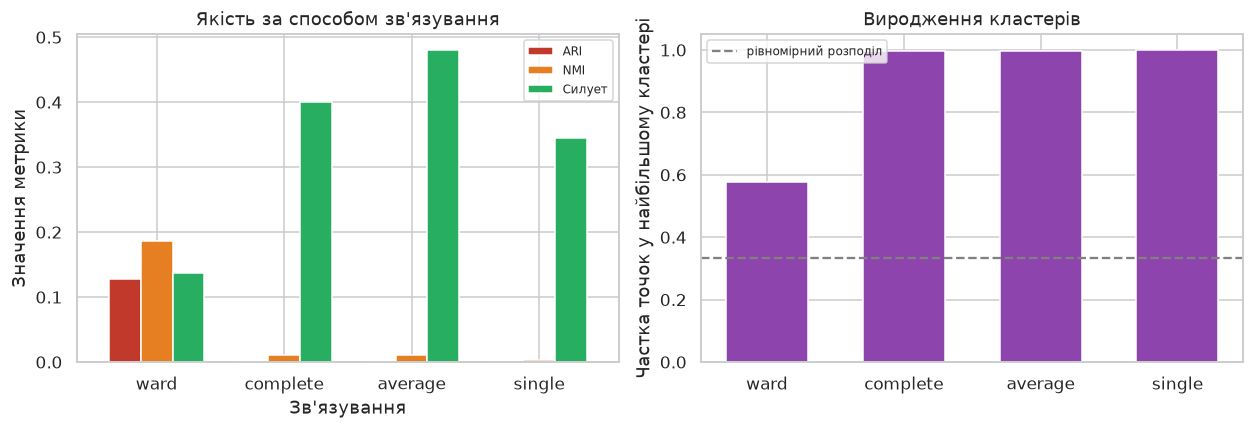

In [10]:
# --- Рисунок 4: порівняння способів зв'язування ---
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
link_df[["ARI", "NMI", "Силует"]].plot.bar(ax=axes[0], rot=0, width=0.75,
                                           color=["#c0392b", "#e67e22", "#27ae60"])
axes[0].set_ylabel("Значення метрики"); axes[0].set_title("Якість за способом зв'язування")
axes[0].legend(fontsize=8)

axes[1].bar(link_df.index, link_df["Найбільший кластер"], color="#8e44ad", width=0.6)
axes[1].axhline(1/3, color="gray", linestyle="--", label="рівномірний розподіл")
axes[1].set_ylabel("Частка точок у найбільшому кластері")
axes[1].set_title("Виродження кластерів"); axes[1].legend(fontsize=8)
axes[1].set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(ASSETS / "04-linkage.png", bbox_inches="tight")
plt.show()

## 5. Залежність від параметрів даних

Досліджуємо два параметри: масштабування ознак і розмірність простору. Для
кластеризації обидва критичні з тієї ж причини, що й для kNN — усе будується на
відстанях.

In [11]:
# 5.1 Масштабування
scale_rows = []
for name, data in [("Без масштабування", X.values),
                   ("StandardScaler", Z)]:
    km = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(data)
    scale_rows.append({
        "Підготовка": name,
        "ARI": adjusted_rand_score(y_true, km.labels_),
        "Силует": silhouette_score(data, km.labels_, sample_size=5000, random_state=RANDOM_STATE),
        "Найбільший кластер": np.bincount(km.labels_).max() / len(y_true),
    })
pd.DataFrame(scale_rows).set_index("Підготовка").round(4)

,ARI,Силует,Найбільший кластер
Підготовка,,,
Без масштабування,0.3155,0.7545,0.5823
StandardScaler,0.2010,0.1054,0.3870


In [12]:
# 5.2 Розмірність: додаємо шумові ознаки
rng = np.random.RandomState(RANDOM_STATE)
noise_dims = [0, 5, 10, 20, 50, 100]
dim_rows = []
sub_i = rng.choice(len(X), 8000, replace=False)
Xb, yb = X.iloc[sub_i].reset_index(drop=True), y_true.iloc[sub_i].reset_index(drop=True)

for d in noise_dims:
    Xd = Xb.copy()
    if d:
        noise = pd.DataFrame(rng.randn(len(Xb), d), columns=[f"n{i}" for i in range(d)])
        Xd = pd.concat([Xd, noise], axis=1)
    Zd_ = StandardScaler().fit_transform(Xd)
    km = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(Zd_)
    dim_rows.append({
        "Шумових ознак": d, "Всього ознак": Xd.shape[1],
        "ARI": adjusted_rand_score(yb, km.labels_),
        "Силует": silhouette_score(Zd_, km.labels_, sample_size=4000, random_state=RANDOM_STATE),
    })

dim_df = pd.DataFrame(dim_rows)
dim_df.to_csv("data/dimensionality.csv", index=False)
dim_df.round(4)

,Шумових ознак,Всього ознак,ARI,Силует
0,0,13,0.1148,0.1376
1,5,18,0.1166,0.0957
2,10,23,0.1166,0.0729
3,20,33,0.1150,0.0496
4,50,63,0.1149,0.0251
5,100,113,0.1132,0.0136


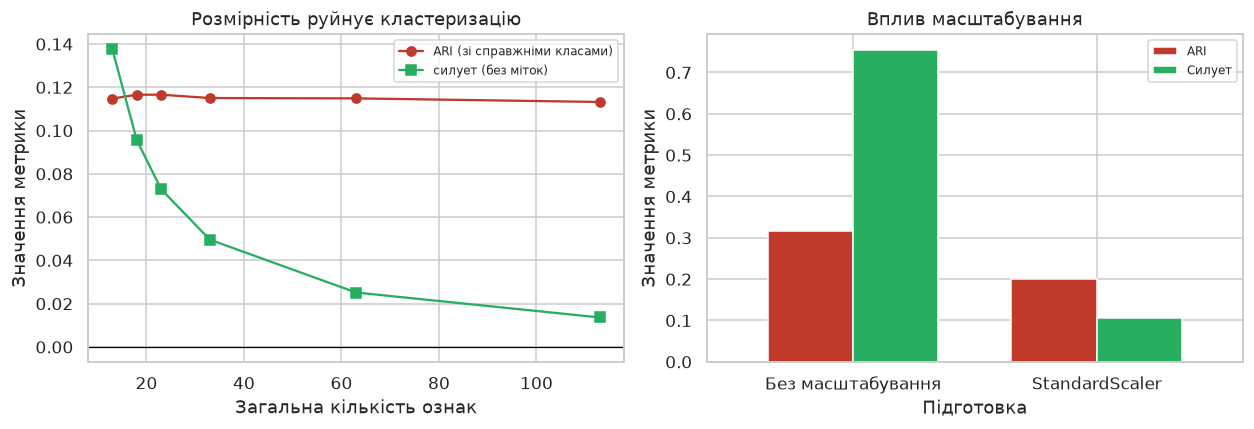

In [13]:
# --- Рисунок 5: вплив параметрів даних ---
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].plot(dim_df["Всього ознак"], dim_df["ARI"], "o-", color="#c0392b", label="ARI (зі справжніми класами)")
axes[0].plot(dim_df["Всього ознак"], dim_df["Силует"], "s-", color="#27ae60", label="силует (без міток)")
axes[0].set_xlabel("Загальна кількість ознак"); axes[0].set_ylabel("Значення метрики")
axes[0].set_title("Розмірність руйнує кластеризацію"); axes[0].legend(fontsize=8)
axes[0].axhline(0, color="black", linewidth=0.8)

sd = pd.DataFrame(scale_rows).set_index("Підготовка")
sd[["ARI", "Силует"]].plot.bar(ax=axes[1], rot=0, width=0.7, color=["#c0392b", "#27ae60"])
axes[1].set_title("Вплив масштабування"); axes[1].set_ylabel("Значення метрики")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "05-data-params.png", bbox_inches="tight")
plt.show()

## 6. Підсумок

In [14]:
summary = pd.DataFrame({
    "Метод": ["k-середніх (k=3)", "Ієрархічна (ward, k=3)",
              "Найкращий k-середніх за ARI", "Для довідки: класифікація (ПЗ № 2)"],
    "ARI": [adjusted_rand_score(y_true, km3.labels_),
            link_df.loc["ward", "ARI"],
            km_df["ARI"].max(),
            np.nan],
    "Примітка": ["справжня кількість класів", f"підвибірка {N_HIER}",
                 f"k = {best_ari}", "точність 0.9943 (з учителем)"],
}).set_index("Метод")
summary.to_csv("data/results-summary.csv")
print(summary.round(4).to_string())
print()
print("Вибір k:");      print(km_df.round(4).to_markdown(index=False)); print()
print("Зв'язування:");  print(link_df.round(4).to_markdown()); print()
print("Розмірність:");  print(dim_df.round(4).to_markdown(index=False))

                                      ARI                      Примітка
Метод                                                                  
k-середніх (k=3)                    0.201     справжня кількість класів
Ієрархічна (ward, k=3)              0.127               підвибірка 5000
Найкращий k-середніх за ARI         0.248                         k = 4
Для довідки: класифікація (ПЗ № 2)    NaN  точність 0.9943 (з учителем)

Вибір k:
|   k |   Інерція |   Силует |    ARI |    NMI |   Однорідність |   Повнота |
|----:|----------:|---------:|-------:|-------:|---------------:|----------:|
|   2 |    232614 |   0.1337 | 0.0867 | 0.1531 |         0.12   |    0.2112 |
|   3 |    215581 |   0.1054 | 0.201  | 0.2159 |         0.2176 |    0.2141 |
|   4 |    198235 |   0.1167 | 0.248  | 0.2614 |         0.2926 |    0.2361 |
|   5 |    181427 |   0.1359 | 0.1803 | 0.2281 |         0.2692 |    0.1979 |
|   6 |    170043 |   0.1496 | 0.1246 | 0.1768 |         0.2282 |    0.1443 |
|   7 |    1